# 4. Trade-offs and robustness

**Goal of this notebook:** pressure-test the six-center recommendation from three directions that notebooks 2 and 3 looked at only one at a time.

1. **Freight and inventory together.** Notebook 2 chose the network on freight alone. Notebook 3 priced the inventory for one network. Here both are priced for networks of 1 to 8 centers, to see what each extra center is really worth.
2. **Would the answer survive different data?** If demand had come out a little differently, or if the model had been built on last half-year's data and used on the next, would it still pick the same sites?
3. **Cost versus speed.** Notebook 2 minimized freight and got faster delivery as a side effect. What if speed is valued directly?

The model code lives in `src/network_model.py` and `src/inventory_model.py`. They are the same calculations as notebooks 2 and 3, packaged as functions, and the tests in `tests/` check that they reproduce those notebooks' saved results exactly.

In [1]:
import sys
sys.path.insert(0, "../src")

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import inventory_model as im
import network_model as nm
from helpers import COLORS, RESULTS, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

data = nm.prepare()            # shipments, rate card, cities, candidate sites
weekly = im.load_weekly_demand()
print(f"{len(data.ship):,} shipments, {data.n_cities:,} cities, {data.n_sites} candidate sites")
print(f"Baseline freight: R$ {data.baseline_cost:,.0f} a year, {data.baseline_transit:.2f} typical days in transit")

84,523 shipments, 3,811 cities, 60 candidate sites
Baseline freight: R$ 1,703,757 a year, 7.26 typical days in transit


`nm.solve_many` runs the optimizer for a list of scenarios, spread across every CPU core. Each scenario is a solve of the same mixed-integer model as in notebook 2.

## Part 1. Freight and inventory together

For each network size, solve for the best sites (freight only, as in notebook 2), then size the inventory those sites need (as in notebook 3) and subtract its holding cost.

In [2]:
sizes = list(range(1, 9))
networks = nm.solve_many([{"n_open": p} for p in sizes])
fc_cost = data.fc_cost()

rows = []
for p, net in zip(sizes, networks):
    assigned = nm.assign_cities(net["sites"], fc_cost, data.direct_cost)
    served_by = {data.cities.at[i, "city_key"]: data.candidates.at[s, "city_key"]
                 for i, s in enumerate(assigned) if s >= 0}
    inv = im.size_inventory(weekly, served_by)
    rows.append({
        "centers": p,
        "freight_saving": net["saving"],
        "holding_cost": inv["holding_cost_all_categories"],
        "safety_stock_units": inv["safety_units"],
        "net_saving": net["saving"] - inv["holding_cost_all_categories"],
        "transit_days": net["transit_days"],
    })

total = pd.DataFrame(rows).set_index("centers")
total["added_net_saving"] = total["net_saving"].diff().fillna(total["net_saving"])
total

,freight_saving,holding_cost,safety_stock_units,net_saving,transit_days,added_net_saving
centers,,,,,,
1,"55,110.51","7,491.52",98.00,"47,618.98",6.76,"47,618.98"
2,"106,387.24","17,271.09",244.00,"89,116.15",6.05,"41,497.17"
3,"136,104.09","34,427.08",493.00,"101,677.01",5.18,"12,560.86"
4,"160,643.89","41,213.31",604.00,"119,430.58",4.83,"17,753.57"
5,"181,179.59","45,866.59",685.00,"135,313.00",4.53,"15,882.42"
6,"200,224.14","51,184.74",776.00,"149,039.40",4.27,"13,726.40"
7,"215,561.63","53,782.02",826.00,"161,779.61",4.12,"12,740.20"
8,"228,904.73","58,901.55",917.00,"170,003.19",3.92,"8,223.58"


**How to read the last column.** `added_net_saving` is what the newest center adds once its inventory is paid for. It is also **the most that center could cost per year to run** (rent, staff, equipment) and still pay for itself. Those running costs are not in the data, so this is the honest way to present the decision.

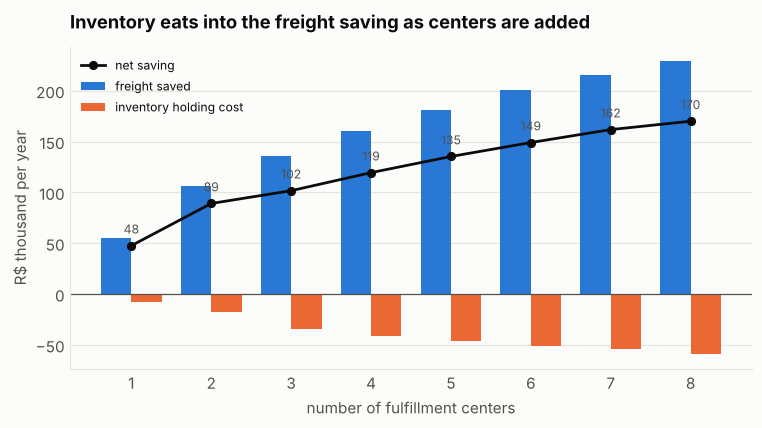

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.array(sizes)
w = 0.38
ax.bar(x - w / 2, total["freight_saving"] / 1000, width=w, color=COLORS["blue"], label="freight saved")
ax.bar(x + w / 2, -total["holding_cost"] / 1000, width=w, color=COLORS["orange"], label="inventory holding cost")
ax.plot(x, total["net_saving"] / 1000, color=COLORS["text"], marker="o", markersize=5, linewidth=1.8, label="net saving")
for xi, v in zip(x, total["net_saving"] / 1000):
    ax.text(xi, v + 12, f"{v:.0f}", ha="center", fontsize=8, color=COLORS["muted"])
ax.axhline(0, color=COLORS["muted"], linewidth=0.8)
ax.set_xticks(sizes)
ax.set_xlabel("number of fulfillment centers")
ax.set_ylabel("R$ thousand per year")
ax.set_title("Inventory eats into the freight saving as centers are added")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "04_freight_vs_inventory.png")
plt.show()

**What this shows.**

- **Holding cost grows faster than the number of centers at first.** Going from 2 to 3 centers doubles it, because the third center (Osasco) takes over the São Paulo metro, the biggest market, and has to carry stock for all of it.
- **The first two centers are worth far more than the rest.** Each adds over R\$40,000 a year net. Centers 3 to 7 add about R\$13,000 to R\$18,000 each. The eighth adds about R\$8,000.
- **So the real question for the business is what a center costs to run.** If a small regional center costs more than about R\$15,000 a year, the case stops at two centers (Salvador and Rio de Janeiro). If it costs less, six or seven make sense.

Remember the dataset is a sample of Olist's orders, so a real business would have far more volume per center and far more room to cover running costs. The comparison between centers is the transferable part.

## Part 2. Would the answer survive different data?

A recommendation that flips when the data moves a little is not worth much. Two tests.

### Test A: resampled demand (bootstrap)

The year's orders are one draw of what could have happened. A **bootstrap** creates other plausible years by resampling the real one: every shipment is counted a random number of times (0, 1, 2, ...), averaging once. Then the model is re-solved on each version.

If the same six sites keep coming back, the choice is driven by the structure of the market, not by luck in which orders happened to be placed.

In [4]:
N_BOOTSTRAP = 40
rng = np.random.default_rng(seed=42)          # fixed seed so the result is repeatable
jobs = [{"n_open": 6, "weights": rng.poisson(1.0, len(data.ship))} for _ in range(N_BOOTSTRAP)]
boot = nm.solve_many(jobs)

base_sites = sorted(networks[5]["site_names"])
site_counts = Counter(name for r in boot for name in r["site_names"])
same_set = sum(sorted(r["site_names"]) == base_sites for r in boot)
savings = np.array([r["saving_pct"] for r in boot])

print(f"Same six sites as the real data in {same_set} of {N_BOOTSTRAP} resampled years")
print(f"Freight saving across resampled years: {savings.mean():.1f}% "
      f"(95% of runs between {np.percentile(savings, 2.5):.1f}% and {np.percentile(savings, 97.5):.1f}%)")
pd.Series(site_counts, name="times chosen").sort_values(ascending=False).to_frame()

Same six sites as the real data in 38 of 40 resampled years
Freight saving across resampled years: 11.8% (95% of runs between 11.7% and 11.9%)


,times chosen
"brasilia, DF",40
"porto alegre, RS",40
"salvador, BA",40
"osasco, SP",40
"nova iguacu, RJ",40
"contagem, MG",38
"belo horizonte, MG",2


Five sites are chosen in every single run. The sixth is Contagem almost every time. In the remaining runs it is Belo Horizonte, the city next door in the same metro area, so in practice the choice is the same.

**One limit of this test:** it reshuffles which orders happened, but keeps the same customers in the same places. It does not test what happens if the market itself shifts. Test B gets closer to that.

### Test B: build on one half-year, use on the next

In real life a network is designed on past data and then used on future demand. So split the year:

- **Design period:** Sep 2017 to Feb 2018. Solve the model on these shipments only.
- **Use period:** Mar to Aug 2018. Measure how that network performs on demand it never saw, and compare with the network that would have been best for that period if it had been known in advance.

The gap between the two is called **regret**: how much is lost by not knowing the future.

In [5]:
first_half = (data.ship["purchased_at"] < "2018-03-01").to_numpy().astype(float)
second_half = 1.0 - first_half
print(f"Design period: {int(first_half.sum()):,} shipments.  Use period: {int(second_half.sum()):,} shipments.")

holdout_rows = []
for p in (2, 4, 6):
    data.set_weights(first_half)                       # design on the first half-year
    designed = nm.best_network(data, p)
    data.set_weights(second_half)                      # then face the second half-year
    cost_second = data.fc_cost()
    in_use = nm.evaluate(data, nm.assign_cities(designed["sites"], cost_second, data.direct_cost), cost_second)
    hindsight = nm.best_network(data, p)               # best possible if the future were known
    holdout_rows.append({
        "centers": p,
        "sites_designed_on_first_half": ", ".join(n.split(",")[0].title() for n in designed["site_names"]),
        "saving_pct_in_use": in_use["saving_pct"],
        "saving_pct_with_hindsight": hindsight["saving_pct"],
        "regret_pct_points": hindsight["saving_pct"] - in_use["saving_pct"],
        "same_sites": sorted(designed["sites"]) == sorted(hindsight["sites"]),
    })
data.set_weights()                                     # back to the full year
holdout = pd.DataFrame(holdout_rows).set_index("centers")
pd.set_option("display.max_colwidth", 120)
holdout

Design period: 39,953 shipments.  Use period: 44,570 shipments.


,sites_designed_on_first_half,saving_pct_in_use,saving_pct_with_hindsight,regret_pct_points,same_sites
centers,,,,,
2,"Salvador, Nova Iguacu",5.91,5.91,0.00,True
4,"Salvador, Osasco, Nova Iguacu, Contagem",9.09,9.09,0.00,True
6,"Brasilia, Porto Alegre, Salvador, Osasco, Nova Iguacu, Contagem",11.34,11.34,0.00,True


**What this shows.** For 2, 4 and 6 centers, the network designed on the first half-year is exactly the network that would have been best for the second half-year with perfect hindsight. The regret is zero. Brazil's demand map is stable enough from one half-year to the next that the sites chosen today would still be the right ones six months later.

## Part 3. Cost versus speed

Notebook 2 minimized freight only, and delivery got faster as a side effect. What if the business also values speed directly? Notebook 1 showed that slow and late orders get much worse reviews, so a day saved is worth something.

The model can include that with one change to the objective. Put a R\$ value on each day an item spends in transit, and minimize

$$\text{freight} + \text{value of a day} \times \text{total item-days in transit}$$

At a value of 0 this is notebook 2's model. As the value rises, the model is willing to spend more freight to deliver faster. Solving it for a range of values traces out the **trade-off curve** between the two goals.

In [6]:
day_values = [0, 1, 2, 5, 10, 25, 100]
tradeoff_runs = nm.solve_many([{"n_open": 6, "value_of_a_day": v} for v in day_values])
tradeoff = pd.DataFrame([{
    "value_of_a_day": v,
    "saving_pct": r["saving_pct"],
    "transit_days": r["transit_days"],
    "pct_items_via_fc": r["pct_items_via_fc"],
    "same_sites_as_freight_only": sorted(r["sites"]) == sorted(networks[5]["sites"]),
} for v, r in zip(day_values, tradeoff_runs)]).set_index("value_of_a_day")
tradeoff

,saving_pct,transit_days,pct_items_via_fc,same_sites_as_freight_only
value_of_a_day,,,,
0,11.75,4.27,74.49,True
1,11.60,4.17,80.13,True
2,11.33,4.14,83.58,True
5,10.88,4.11,87.10,True
10,10.66,4.10,88.99,True
25,10.48,4.10,90.46,True
100,10.08,4.09,91.29,False


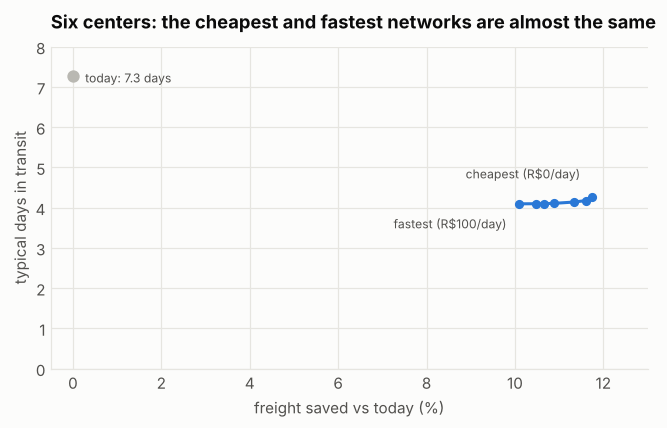

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
# today's network for scale: no saving, 7.3 days
ax.scatter([0], [data.baseline_transit], color=COLORS["gray"], s=50, zorder=3)
ax.annotate(f"today: {data.baseline_transit:.1f} days", (0, data.baseline_transit), xytext=(8, -4),
            textcoords="offset points", fontsize=8, color=COLORS["muted"])
# the whole trade-off curve, drawn on axes that start at zero so its true size shows
ax.plot(tradeoff["saving_pct"], tradeoff["transit_days"], color=COLORS["blue"], marker="o", markersize=5, zorder=4)
first, last = tradeoff.iloc[0], tradeoff.iloc[-1]
ax.annotate("cheapest (R$0/day)", (first["saving_pct"], first["transit_days"]), xytext=(-8, 12),
            textcoords="offset points", fontsize=8, color=COLORS["muted"], ha="right")
ax.annotate("fastest (R$100/day)", (last["saving_pct"], last["transit_days"]), xytext=(-8, -16),
            textcoords="offset points", fontsize=8, color=COLORS["muted"], ha="right")
ax.set_xlim(-0.5, 13)
ax.set_ylim(0, 8)
ax.set_xlabel("freight saved vs today (%)")
ax.set_ylabel("typical days in transit")
ax.set_title("Six centers: the cheapest and fastest networks are almost the same")
save_figure(fig, "04_cost_vs_speed.png")
plt.show()

**What this shows.** The curve is short. Going from the freight-only network to the fastest one gives up under 2 percentage points of freight saving to gain under 0.2 days of transit time. And the sites barely change: the extra speed comes from sending more cities through the same centers, not from picking different centers.

That is a useful result for a business decision. **The cheapest network and the fastest network are nearly the same network**, so there is no hard trade-off to argue about between the finance team and the customer-experience team.

## Save the results

In [8]:
total.to_csv(RESULTS / "total_cost_by_centers.csv")
pd.Series(site_counts, name="times_chosen").to_csv(RESULTS / "bootstrap_site_counts.csv")
holdout.to_csv(RESULTS / "holdout_regret.csv")
tradeoff.to_csv(RESULTS / "cost_vs_speed.csv")
print("Saved 4 files to results/")

Saved 4 files to results/


## What we learned

1. **The first two centers carry the business case.** Net of inventory, each adds over R\$40,000 a year. Later centers add R\$8,000 to R\$18,000 each, so whether six is right depends on what a center costs to run.
2. **The site choice is robust.** Five of the six sites came back in all 40 resampled years, and the sixth was the same metro area every time. A network designed on one half-year was exactly the best network for the next half-year.
3. **Cheap and fast point the same way.** Valuing speed directly barely changes the sites. It mainly routes more cities through the same centers.

## Limits of this notebook

- Running costs of a center are still unknown. They are reported as a break-even figure rather than assumed.
- The bootstrap keeps customers in the same places. Test B is a better test of a changing market, but six months is a short horizon.
- The value of a day in transit is a choice, not a measured number. That is why the whole curve is shown rather than one point on it.